# Humidity and air-conditioning baseline

> **Before running:** run [`../data-cleaning/main.ipynb`](../data-cleaning/main.ipynb) from the `data-cleaning` folder first. This notebook requires all 14 cleaned floor/year CSVs in `data-cleaning/outputs/clean/`. It deliberately does not read the raw `data/` files or fall back to precomputed analytics.

This baseline supports the proposal question: **How can seasonal weather changes, air-con performance, and humidity levels be analysed to detect zones at risk of air-con degradation and mould growth?** The proposal's sensor scope is Floors 3–7, zones 1, 2, 4, and 5.

## Method and assumptions

1. Read cleaned minute-level AC power, temperature, and relative humidity (RH) for proposal-scope zones. An AC sum is valid only when all recorded AC meters for that zone are present; sensor values are retained only when all matching sensor columns are present.
2. Summarise RH exposure by month and zone, including mean and 95th-percentile RH, the share of valid minutes above 60%, and continuous high-RH episodes. Missing or below-threshold minutes break an episode. Also show sensitivity at 65% and 70% RH and count episodes lasting at least six hours.
3. Summarise hourly AC/RH/temperature profiles. Weekdays 08:00–17:59 are shown only as an assumed schedule proxy; the dataset has no occupancy or operating-state labels.
4. Import hourly Bangkok ERA5 weather from the Open-Meteo Archive API (outdoor temperature, relative humidity, dew point, and precipitation), then align it with indoor hourly observations. Monthly and year-on-year summaries include the matching weather context.
5. Compare matching July–December calendar months in 2018 and 2019 as a descriptive comparison with outdoor-weather context. This is not a causal or fully weather-normalised degradation estimate.

**Weather source:** Open-Meteo [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), ERA5 hourly model, Bangkok coordinates (13.7563, 100.5018), local time `Asia/Bangkok`, 1 July 2018–31 December 2019. The first run needs internet access and saves a local CSV cache under `baseline/data/`; later runs use that cache. Delete the cache to re-download it.

**Important limitations:** outdoor weather is a city-level reanalysis estimate, not a rooftop/site weather station. Occupancy, maintenance records, and equipment-failure labels are still absent. The AC-kW-per-positive-outdoor/indoor-temperature-difference column is an exploratory descriptive ratio, not a calibrated efficiency metric. These data cannot validate mould risk or support a forecast/RUL model. High RH is an inspection-screening signal only, not a diagnosis or prediction.

In [1]:
from pathlib import Path
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
repo_root = next(
    (path for path in candidates if (path / "data-cleaning").is_dir() and (path / "baseline").is_dir()),
    None,
)
if repo_root is None:
    raise FileNotFoundError(
        "Could not locate the repository. Open this notebook from the project "
        "folder, or set the notebook working directory to the repository root."
    )

baseline_dir = repo_root / "baseline"
sys.path.insert(0, str(baseline_dir))
from _shared import clean_data_directory

clean_dir = clean_data_directory()
print(f"Using cleaned inputs from: {clean_dir}")

C:\Users\panhc\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Using cleaned inputs from: C:\Y4S1\SBA\SBA_BQ2\data-cleaning\outputs\clean


## Import Bangkok ERA5 weather

The request is for hourly ERA5 data through the Open-Meteo Archive API for the same 18-month window as the building dataset. The retrieved series is checked for required fields, unique timestamps, and full hourly coverage before it is used.

In [2]:
from IPython.display import display
from humidity_risk_baseline import load_bangkok_era5_weather

weather_cache = baseline_dir / "data" / "bangkok_era5_hourly_2018-2019.csv"
weather = load_bangkok_era5_weather(weather_cache)
display(weather.head())
display(weather.describe().T)

Downloaded and cached Open-Meteo ERA5 weather: C:\Y4S1\SBA\SBA_BQ2\baseline\data\bangkok_era5_hourly_2018-2019.csv


,outdoor_temp_C,outdoor_rh_pct,outdoor_dew_point_C,precipitation_mm
Date,,,,
2018-07-01 00:00:00,27.1,89,25.1,0.0
2018-07-01 01:00:00,27.1,86,24.6,0.0
2018-07-01 02:00:00,26.9,85,24.2,0.0
2018-07-01 03:00:00,26.5,86,24.0,0.0
2018-07-01 04:00:00,26.3,87,24.0,0.0


,count,mean,std,min,25%,50%,75%,max
outdoor_temp_C,13176.0,29.017714,3.011021,17.5,27.0,28.8,31.1,39.5
outdoor_rh_pct,13176.0,75.016090,12.845160,35.0,66.0,77.0,85.0,99.0
outdoor_dew_point_C,13176.0,23.852634,2.247910,9.9,23.4,24.5,25.2,28.5
precipitation_mm,13176.0,0.137568,0.499638,0.0,0.0,0.0,0.0,8.9


## Weather-informed baseline tables

The monthly and hourly tables align outdoor conditions with indoor humidity, temperature, and AC power. The inspection screen is ordered by observed high-humidity exposure and longest monthly episode; it is not a validated composite risk score. Year-on-year comparisons include weather summaries but are still descriptive and not a causal adjustment.

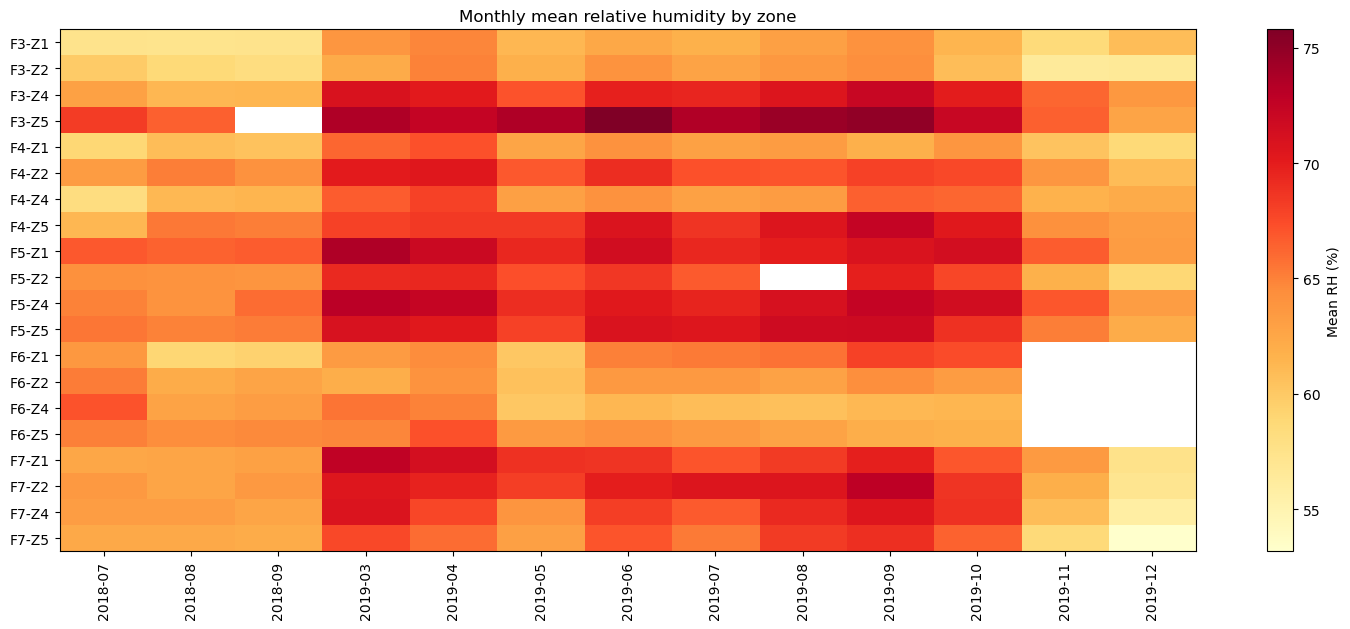

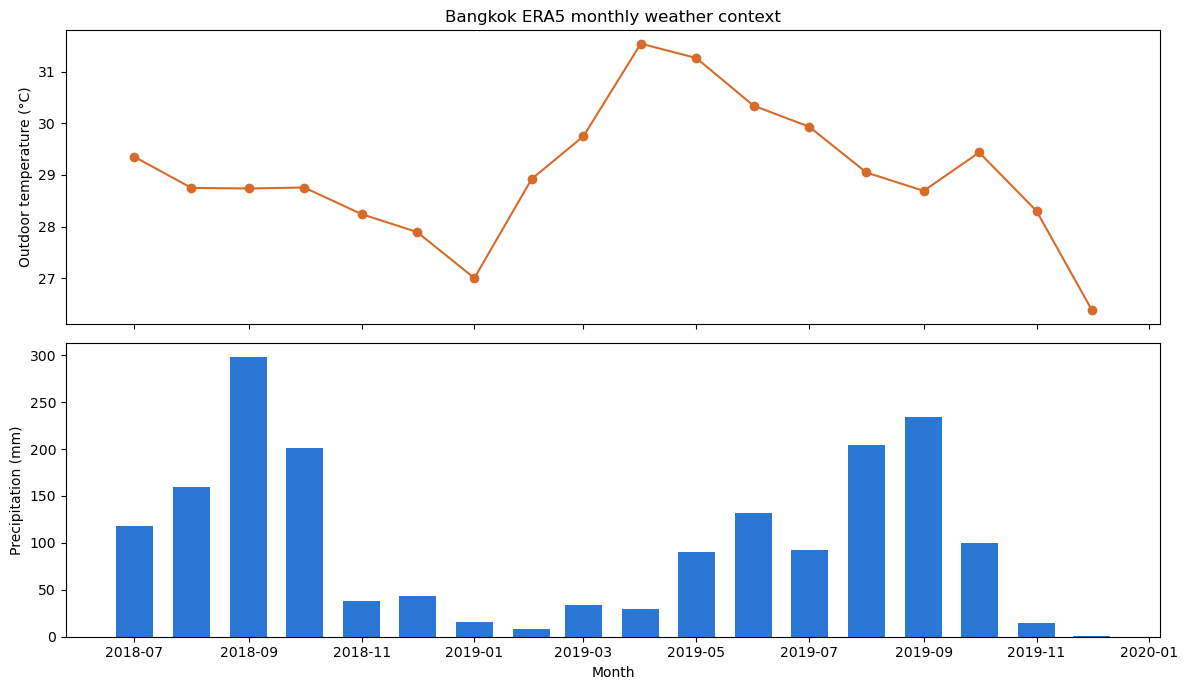

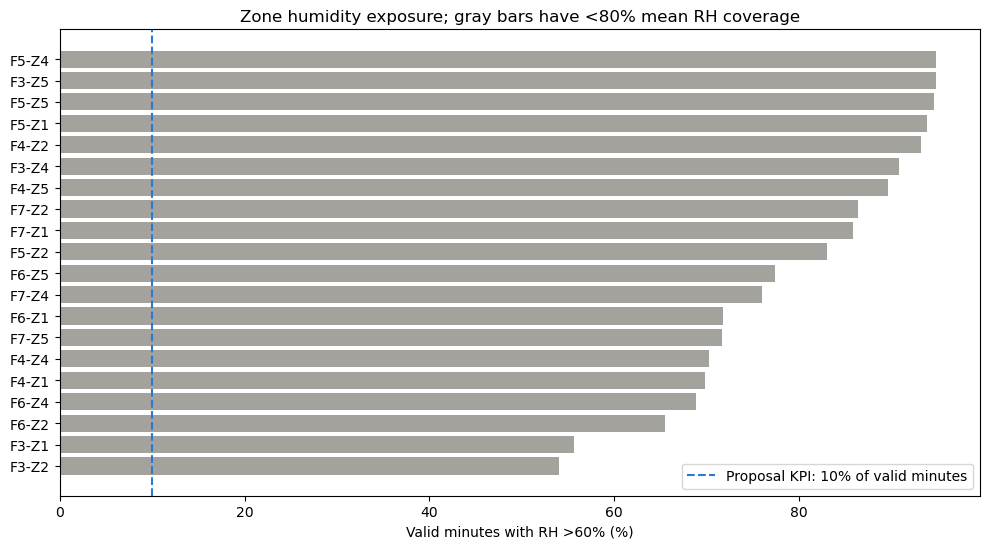

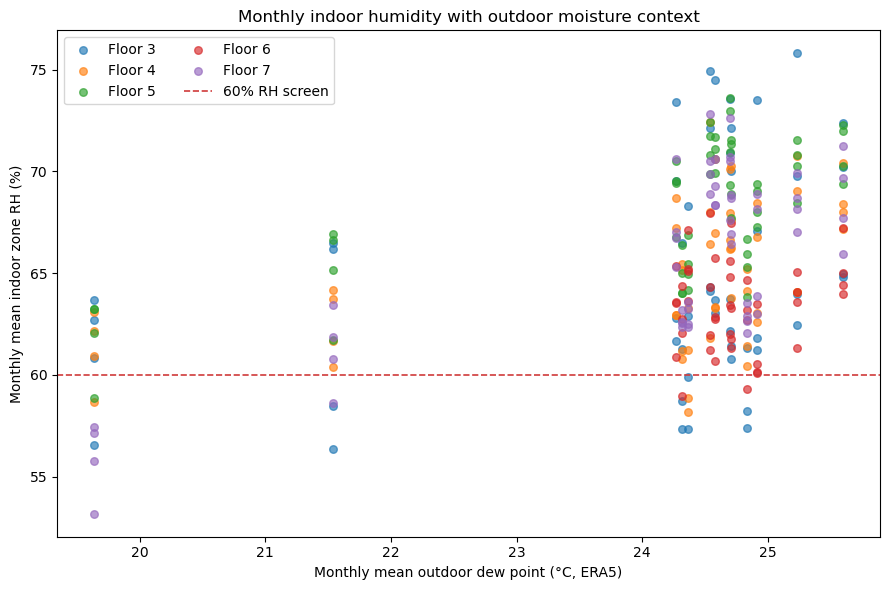

,floor,zone,average_high_rh_share_pct,worst_month_high_rh_share_pct,longest_monthly_episode_minutes,total_episodes_at_least_6h,valid_rh_minutes,minutes_rh_above_60,average_rh_coverage_pct,months_with_rh_data,average_ac_kW,average_temp_C,average_outdoor_temp_C,average_outdoor_rh_pct,total_precipitation_mm,average_ac_kW_per_cooling_degree,valid_minutes_above_60_pct
10,5,4,94.810391,100.000000,9834,248,501453,475909,63.097110,13,3.685176,24.597010,29.020351,75.03132,1812.6,0.677746,94.906003
3,3,5,95.540794,99.902018,9281,248,446293,423341,56.162522,12,1.859876,23.692112,29.020351,75.03132,1812.6,0.271648,94.857190
11,5,5,94.834074,100.000000,16021,285,527744,499600,66.461283,13,1.740591,25.351121,29.020351,75.03132,1812.6,0.587167,94.667111
8,5,1,94.725070,100.000000,10043,206,464923,436639,58.476072,13,5.274117,24.382647,29.020351,75.03132,1812.6,0.423807,93.916412
5,4,2,93.688001,99.857570,11648,211,523234,487798,65.860286,13,3.399973,24.748586,29.020351,75.03132,1812.6,0.617183,93.227504
2,3,4,89.828065,99.993215,13266,231,525944,478221,66.231112,13,3.856611,24.011454,29.020351,75.03132,1812.6,0.849588,90.926220
7,4,5,89.456093,99.871182,9702,264,527405,472824,66.425080,13,1.744341,24.588597,29.020351,75.03132,1812.6,0.363317,89.651027
17,7,2,86.445700,99.995446,9248,258,533309,460780,67.158731,13,6.285741,25.893919,29.020351,75.03132,1812.6,9.661674,86.400192
16,7,1,85.546303,99.287490,10075,297,529094,454546,66.619678,13,8.536488,24.842139,29.020351,75.03132,1812.6,1.468558,85.910254
9,5,2,85.001100,96.644390,6609,235,407134,338372,51.276620,12,3.519235,24.926538,29.020351,75.03132,1812.6,0.573809,83.110720


,floor,zone,year,month,valid_rh_minutes,rh_coverage_pct,mean_rh_pct,p95_rh_pct,minutes_rh_above_60,high_rh_share_of_valid_pct,...,longest_high_rh_episode_minutes,episodes_at_least_6h,mean_ac_kW,mean_ac_kW_rh_above_60,mean_temp_C,mean_outdoor_temp_C,mean_outdoor_rh_pct,mean_outdoor_dew_point_C,total_precipitation_mm,mean_ac_kW_per_cooling_degree
0,3,1,2018,7,44640,100.000000,57.358407,63.98,10579,23.698477,...,3762,5,4.779493,0.960145,27.538077,29.354704,75.278226,24.360215,117.7,2.100689
1,3,1,2018,8,43933,98.416219,57.325972,64.80,10563,24.043430,...,2731,4,5.047668,0.923389,27.288092,28.749731,77.655914,24.314113,159.8,2.491191
2,3,1,2018,9,16425,38.020833,57.394121,63.16,4431,26.977169,...,1683,3,4.880218,0.903636,26.819611,28.739167,80.308333,24.834444,297.6,2.117437
3,3,1,2018,10,0,0.000000,NaN,NaN,0,NaN,...,0,0,5.512908,NaN,NaN,28.757661,80.990591,24.953360,201.0,NaN
4,3,1,2018,11,0,0.000000,NaN,NaN,0,NaN,...,0,0,6.357252,NaN,NaN,28.242500,75.361111,23.177083,37.7,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,7,5,2019,8,44471,99.621416,68.331650,75.58,41019,92.237638,...,3766,29,2.697060,2.325153,25.382212,29.048790,77.543011,24.575000,204.2,0.571330
356,7,5,2019,9,42664,98.759259,68.910646,76.30,39610,92.841740,...,4427,28,2.098229,1.837289,25.492614,28.692639,79.338889,24.541667,234.3,0.413932
357,7,5,2019,10,44138,98.875448,66.416116,75.10,37249,84.392134,...,3663,22,2.474439,1.393260,26.384340,29.436559,76.942204,24.701613,99.9,0.457797
358,7,5,2019,11,42550,98.495370,58.637585,71.18,14601,34.314924,...,1998,16,2.074945,0.825265,25.468862,28.303194,68.536111,21.542500,14.6,0.607617


,floor,zone,month,mean_ac_kW_2018,mean_ac_kW_2019,mean_rh_pct_2018,mean_rh_pct_2019,high_rh_share_of_valid_pct_2018,high_rh_share_of_valid_pct_2019,mean_ac_kW_2019_minus_2018,mean_rh_pct_2019_minus_2018,high_rh_share_of_valid_pct_2019_minus_2018
0,3,1,7,4.779493,4.574763,57.358407,61.677169,23.698477,61.737372,-0.204729,4.318761,38.038895
1,3,1,8,5.047668,4.574235,57.325972,63.037252,24.043430,70.963645,-0.473432,5.711280,46.920215
2,3,1,9,4.880218,4.700669,57.394121,64.123416,26.977169,78.929640,-0.179549,6.729295,51.952471
3,3,1,10,5.512908,4.739267,NaN,61.422346,NaN,55.713928,-0.773641,NaN,NaN
4,3,1,11,6.357252,4.417214,NaN,58.488689,NaN,31.884844,-1.940037,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
115,7,5,8,2.870908,2.697060,62.337250,68.331650,68.722836,92.237638,-0.173848,5.994401,23.514802
116,7,5,9,2.930846,2.098229,62.062594,68.910646,67.095224,92.841740,-0.832616,6.848052,25.746516
117,7,5,10,2.543594,2.474439,NaN,66.416116,NaN,84.392134,-0.069155,NaN,NaN
118,7,5,11,2.388551,2.074945,NaN,58.637585,NaN,34.314924,-0.313607,NaN,NaN


,floor,zone,hour,mean_rh_pct,mean_ac_kW,mean_outdoor_temp_C,mean_outdoor_rh_pct,mean_outdoor_dew_point_C,mean_precipitation_mm,mean_ac_kw_per_cooling_degree,valid_hours
0,3,1,8,60.607112,24.569568,26.366837,85.392857,23.668367,0.092857,8.566007,249
1,3,1,9,57.998838,21.390582,30.569898,66.645408,23.543622,0.076020,2.640450,248
2,3,1,10,57.425784,20.778149,30.624745,66.862245,23.650000,0.065561,2.520018,246
3,3,1,11,57.144084,11.741290,30.612755,67.045918,23.685969,0.098469,1.523707,244
4,3,1,12,57.562716,0.102291,32.773214,58.627551,23.450765,0.135204,0.017960,243
...,...,...,...,...,...,...,...,...,...,...,...
195,7,5,13,60.312518,11.191895,32.810204,58.670918,23.489541,0.148724,1.342630,252
196,7,5,14,59.620845,9.741344,32.838265,58.464286,23.458163,0.106633,0.926785,253
197,7,5,15,60.230736,8.283374,32.603316,59.375000,23.452041,0.143112,0.816008,253
198,7,5,16,60.101469,7.045201,32.541582,59.364796,23.367092,0.319133,0.693946,254


,floor,zone,rh_threshold_pct,valid_minutes,minutes_above_threshold,share_of_valid_minutes_pct,episodes,longest_episode_minutes,episodes_at_least_6h
0,3,1,60.0,502936,279817,55.636701,1366,4199,206
1,3,2,60.0,520234,281253,54.062787,1201,5188,206
2,3,4,60.0,525944,478221,90.926220,739,13266,231
3,3,5,60.0,446293,423341,94.857190,785,9281,248
4,4,1,60.0,531507,371504,69.896351,1784,5347,279
5,4,2,60.0,523234,487798,93.227504,480,11648,211
6,4,4,60.0,441191,309993,70.262766,2272,8274,228
7,4,5,60.0,527405,472824,89.651027,1652,9702,264
8,5,1,60.0,464923,436639,93.916412,505,10043,206
9,5,2,60.0,407134,338372,83.110720,1930,6609,235


,month_start,mean_outdoor_temp_C,mean_outdoor_rh_pct,mean_outdoor_dew_point_C,total_precipitation_mm,valid_weather_hours
0,2018-07-01,29.354704,75.278226,24.360215,117.7,744
1,2018-08-01,28.749731,77.655914,24.314113,159.8,744
2,2018-09-01,28.739167,80.308333,24.834444,297.6,720
3,2018-10-01,28.757661,80.990591,24.953360,201.0,744
4,2018-11-01,28.242500,75.361111,23.177083,37.7,720
5,2018-12-01,27.895430,74.373656,22.622849,43.6,744
6,2019-01-01,27.004032,71.918011,21.119758,15.7,744
7,2019-02-01,28.922768,77.639881,24.370833,7.9,672
8,2019-03-01,29.751210,75.696237,24.694355,34.3,744
9,2019-04-01,31.543333,72.000000,25.593056,29.3,720


Tables and chart saved under: C:\Y4S1\SBA\SBA_BQ2\baseline\outputs


In [3]:
from humidity_risk_baseline import run_humidity_baseline

results = run_humidity_baseline(weather)
display(results["inspection_screen"])
display(results["monthly_baseline"])
display(results["year_comparison"])
display(results["assumed_occupied_profile"])
display(results["threshold_sensitivity"])
display(results["weather_monthly"])
print(f"Tables and chart saved under: {results['output_directory']}")

## Baseline summary

The summary below uses all valid minute-level RH observations for the 20 proposal-scope zones, compares the observed high-RH share with the proposal's 10% KPI, and reports the coverage available to support that baseline. Weather values are city-level ERA5 context, not a local roof measurement. Elevated RH is an inspection signal, not a mould diagnosis; higher AC power is not proof of degradation.

In [4]:
import numpy as np
import pandas as pd

monthly = results["monthly_baseline"]
screen = results["inspection_screen"]
expected_months = pd.period_range("2018-07", "2019-12", freq="M")
expected_rh_minutes = len(screen) * sum(period.days_in_month * 24 * 60 for period in expected_months)
valid_rh_minutes = int(monthly["valid_rh_minutes"].sum())
high_rh_minutes = int(monthly["minutes_rh_above_60"].sum())
coverage_zones = screen.loc[screen["average_rh_coverage_pct"] >= 80]
top_zone = screen.iloc[0]
longest_minutes = int(monthly["longest_high_rh_episode_minutes"].max())
weighted_mean_rh = np.average(
    monthly["mean_rh_pct"].fillna(0),
    weights=monthly["valid_rh_minutes"],
)

humidity_summary = pd.DataFrame([
    {"Baseline measure": "Proposal-scope zones", "Value": f"{len(screen)}"},
    {"Baseline measure": "Valid RH coverage across zone-minutes", "Value": f"{valid_rh_minutes / expected_rh_minutes:.1%}"},
    {"Baseline measure": "Zone-months with any valid RH data", "Value": f"{(monthly['rh_coverage_pct'] > 0).sum()} / {len(monthly)}"},
    {"Baseline measure": "Zones with >=80% average RH coverage", "Value": f"{len(coverage_zones)} / {len(screen)}"},
    {"Baseline measure": "Valid-observation-weighted indoor mean RH", "Value": f"{weighted_mean_rh:.1f}%"},
    {"Baseline measure": "Valid RH minutes above 60%", "Value": f"{high_rh_minutes / valid_rh_minutes:.1%} (proposal KPI: <10%)"},
    {"Baseline measure": "Zones below 10% high-RH exposure", "Value": f"{screen['valid_minutes_above_60_pct'].lt(10).sum()} / {len(screen)}"},
    {"Baseline measure": "Episodes >=6 hours with RH >60%", "Value": f"{int(screen['total_episodes_at_least_6h'].sum()):,}"},
    {"Baseline measure": "Longest observed continuous high-RH episode", "Value": f"{longest_minutes:,} minutes ({longest_minutes / 1440:.1f} days)"},
    {"Baseline measure": "Highest zone-level valid-minute exposure", "Value": f"F{int(top_zone['floor'])}-Z{int(top_zone['zone'])}: {top_zone['valid_minutes_above_60_pct']:.1f}%"},
    {"Baseline measure": "Mean outdoor temperature / RH (ERA5)", "Value": f"{weather['outdoor_temp_C'].mean():.1f} °C / {weather['outdoor_rh_pct'].mean():.1f}%"},
    {"Baseline measure": "ERA5 precipitation total", "Value": f"{weather['precipitation_mm'].sum():.1f} mm (18 months)"},
])
display(screen[["floor", "zone", "valid_minutes_above_60_pct", "average_rh_coverage_pct", "months_with_rh_data", "longest_monthly_episode_minutes", "total_episodes_at_least_6h"]].head(10).round(1))
display(humidity_summary)

,floor,zone,valid_minutes_above_60_pct,average_rh_coverage_pct,months_with_rh_data,longest_monthly_episode_minutes,total_episodes_at_least_6h
10,5,4,94.9,63.1,13,9834,248
3,3,5,94.9,56.2,12,9281,248
11,5,5,94.7,66.5,13,16021,285
8,5,1,93.9,58.5,13,10043,206
5,4,2,93.2,65.9,13,11648,211
2,3,4,90.9,66.2,13,13266,231
7,4,5,89.7,66.4,13,9702,264
17,7,2,86.4,67.2,13,9248,258
16,7,1,85.9,66.6,13,10075,297
9,5,2,83.1,51.3,12,6609,235


,Baseline measure,Value
0,Proposal-scope zones,20
1,Valid RH coverage across zone-minutes,61.4%
2,Zone-months with any valid RH data,250 / 360
3,Zones with >=80% average RH coverage,0 / 20
4,Valid-observation-weighted indoor mean RH,65.5%
5,Valid RH minutes above 60%,79.7% (proposal KPI: <10%)
6,Zones below 10% high-RH exposure,0 / 20
7,Episodes >=6 hours with RH >60%,"4,863"
8,Longest observed continuous high-RH episode,"16,021 minutes (11.1 days)"
9,Highest zone-level valid-minute exposure,F5-Z4: 94.9%
